# t-SNE of ESMC-600M Embeddings: unknown vs wzx vs wzy

This notebook loads protein embeddings from three CSV files and visualises them together
in 2D using t-SNE:

| File | Label | Colour |
|---|---|---|
| `data/esmc600m_embeddings.csv` | **unknown** | grey |
| `data/esmc600m_embeddings_wzx.csv` | **wzx** | red |
| `data/esmc600m_embeddings_wzy.csv` | **wzy** | green |

Each CSV has one row per protein: an `id` column followed by 1152 embedding dimensions
(`dim_0` ... `dim_1151`). No external annotations are used.

In [45]:
import warnings

import numpy as np
import pandas as pd
import plotly.express as px
from sklearn.manifold import TSNE
from Bio import SeqIO

## Load the three embedding files and combine them

Each file gets its label from the filename, then all rows are concatenated into a
single dataframe.

In [46]:
FILES = {
    "other": "data/esmc600m_embeddings.csv",
    "wzx": "data/esmc600m_embeddings_wzx.csv",
    "wzy": "data/esmc600m_embeddings_wzy.csv",
}
hits = pd.read_csv("wzx_wzy_labels/matched_labels.tsv", sep="\t") #proteins in all_prot_2.faa similar to wzx/wzy alleles in ecoh
inclusion = pd.read_csv("inclusion_list.txt", header=None) #list of cannonical O-antigen loci
exclusion = pd.read_csv("exclusion_list.csv") #exclude products which are flippases or polymerases
final_list = []
for record in SeqIO.parse("dedup_pipeline/results/deduplicated_combined.faa", "fasta"):
    final_list.append(record.id)
frames = []
for label, path in FILES.items():
    frame = pd.read_csv(path)
    # Inserting one column into a 1152-column frame is fine here; the warning is noise
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", pd.errors.PerformanceWarning)
        frame["label"] = label
    frames.append(frame)
    print(f"{label}: {frame.shape[0]} proteins")

df = pd.concat(frames, ignore_index=True).copy()  # .copy() defragments the wide frame
has_pipe = df['id'].str.contains('|', regex=False)
locus = df['id'].str.split('|', n=1).str[0]
mask = (locus.isin(inclusion.iloc[:, 0])) | (~has_pipe)
df = df[mask]


has_pipe = df['id'].str.contains('|', regex=False)
locus = df['id'].str.split('|', n=1).str[1]
mask = locus.isin(exclusion.iloc[:, 0]) & has_pipe
df = df[~mask]


df = df[~df['id'].str.contains('novel', case=False, na=False)]


df = df[~df['id'].isin(hits["query"])]
df = df[df['id'].isin(final_list)]
print(f"Total: {df.shape[0]} proteins with {df.shape[1] - 2} embedding dimensions")

other: 2724 proteins
wzx: 244 proteins
wzy: 242 proteins
Total: 1517 proteins with 1152 embedding dimensions


## Run t-SNE

Same parameters as the other notebooks (perplexity 30, PCA init, fixed random state)
so the layout is reproducible.

In [71]:
loci = []
for value in df.id:
    if "|" in value:

        loci.append(value.split("|")[0])


loci = list(set(loci))

loci = pd.DataFrame(loci)
loci.to_csv("established_loci_training.csv", index=True)

In [47]:
X = df.filter(like="dim_").to_numpy(dtype=np.float32)
# default random is 42
tsne = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    learning_rate="auto",
    random_state=42,
)
df[["tsne_1", "tsne_2"]] = tsne.fit_transform(X)
print("t-SNE done")

t-SNE done


## Interactive plot

Hover over any point to see its protein ID and label. Use the toolbar to zoom/pan,
and click legend entries to toggle groups.

In [48]:
# Draw order: grey unknowns in the background, wzx/wzy on top
label_order = ["other", "wzx", "wzy"]
df["label"] = pd.Categorical(df["label"], categories=label_order, ordered=True)
df = df.sort_values("label")

fig = px.scatter(
    df,
    x="tsne_1",
    y="tsne_2",
    color="label",
    color_discrete_map={
        "other": "grey",
        "wzx": "red",
        "wzy": "green",
    },
    category_orders={"label": label_order},
    hover_data={
        "id": True,
        "label": True,
        "tsne_1": False,
        "tsne_2": False,
    },
    labels={
        "id": "Protein ID",
        "label": "Label",
    },
    title="t-SNE of ESMC-600M embeddings: unknown vs wzx vs wzy",
    width=1000,
    height=800,
    opacity=0.7,
)
fig.update_traces(marker={"size": 5})
fig.update_layout(
    xaxis_title="t-SNE dimension 1",
    yaxis_title="t-SNE dimension 2",
    legend_title="Label",
)
fig.update_layout(template="plotly_white")
fig.show()

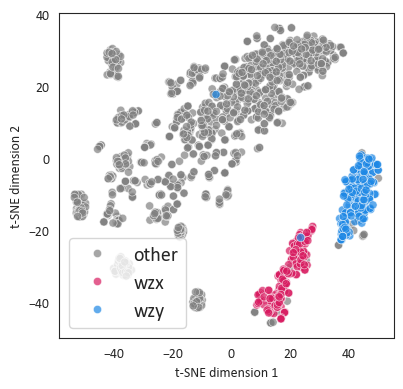

In [49]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib as mpl
sns.set_style("white")
plt.rcParams['svg.fonttype'] = 'none'

# Set global font to Calibri
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Calibri']
fig, ax = plt.subplots(figsize=(4.135, 4))
sns.scatterplot(
    data=df,
    x="tsne_1",
    y="tsne_2",
    hue="label",
    hue_order=label_order,
    palette={"other": "grey", "wzx": "#D81B60", "wzy": "#1E88E5"},
    alpha=0.7,
    s=35,
    ax=ax,
)
ax.set(
    xlabel="t-SNE dimension 1",
    ylabel="t-SNE dimension 2",
)
ax.legend(fontsize="x-large")
plt.tight_layout()
plt.savefig("tsne_wzx_wzy.svg", format="svg")
plt.show()

In [50]:
from sklearn.model_selection import train_test_split
import joblib
import numpy as np
import pandas as pd
import plotly.express as px
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import LeaveOneOut, cross_val_score

loo = LeaveOneOut()
X = df.filter(like="dim_").to_numpy(dtype=np.float32)
y = df["label"].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(f"Train: {X_train.shape[0]} proteins | Test: {X_test.shape[0]} proteins")


Train: 1213 proteins | Test: 304 proteins


Classification Accuracy: 0.99


KeyboardInterrupt: 

In [72]:

model = make_pipeline(
        StandardScaler(),
        MLPClassifier(
        hidden_layer_sizes=(58),
        max_iter=500,
        #verbose=True,
        random_state=42,
    ),)
model.fit(X_train, y_train)
scores = cross_val_score(model, X_train, y_train, cv=5)
print(f"Train accuracy: {model.score(X_train, y_train):.3f}")


Train accuracy: 1.000


In [54]:
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

       other       1.00      1.00      1.00       235
         wzx       0.97      1.00      0.99        34
         wzy       1.00      0.97      0.99        35

    accuracy                           0.99       304
   macro avg       0.99      0.99      0.99       304
weighted avg       0.99      0.99      0.99       304



In [55]:
labels = model.classes_
cm = confusion_matrix(y_test, y_pred, labels=labels)

fig = px.imshow(
    cm,
    x=labels,
    y=labels,
    text_auto=True,
    color_continuous_scale="Blues",
    labels={"x": "Predicted label", "y": "True label", "color": "Count"},
    title="Confusion matrix MLP",
    width=600,
    height=550,
)
fig.update_layout(template="plotly_white")
fig.show()

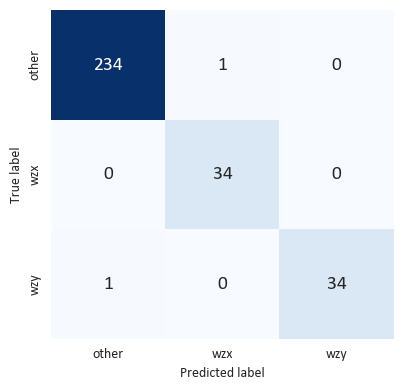

In [56]:
sns.set_style("white")
plt.rcParams['svg.fonttype'] = 'none'

# Set global font to Calibri
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Calibri']
fig, ax = plt.subplots(figsize=(4.135, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
    ax=ax,
    cbar=False,
    annot_kws={"size": 14}
)
ax.set(
    xlabel="Predicted label",
    ylabel="True label",


)
plt.tight_layout()
plt.savefig("matrix_wzx_wzy.svg", format="svg")
plt.show()

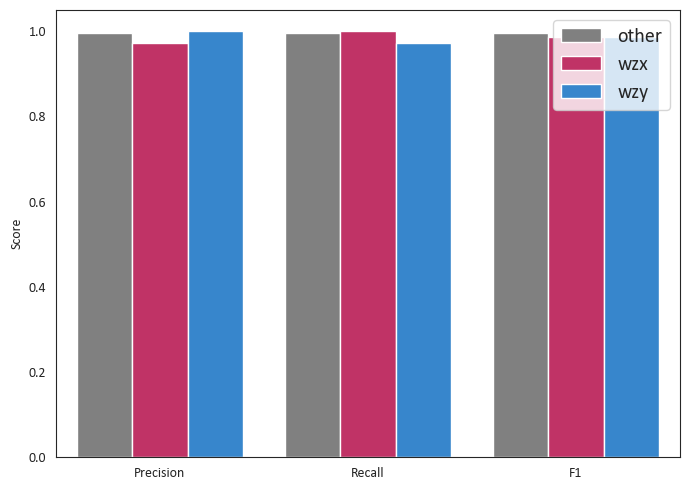

In [57]:
from sklearn.metrics import precision_recall_fscore_support

colors = {"other": "grey", "wzx": "#D81B60", "wzy": "#1E88E5"}
prec, rec, f1, _ = precision_recall_fscore_support(
    y_test, y_pred, labels=labels, zero_division=0
)
metrics_df = pd.DataFrame(
    {
        "metric": np.repeat(["Precision", "Recall", "F1"], len(labels)),
        "label": np.tile(labels, 3),
        "score": np.concatenate([prec, rec, f1]),
    }
)

fig, ax = plt.subplots(figsize=(7, 5))
sns.barplot(
    data=metrics_df,
    x="metric",
    y="score",
    hue="label",
    palette=colors,
    ax=ax,
)
ax.set(xlabel="", ylabel="Score")
ax.set_ylim(0, 1.05)
ax.legend(fontsize="x-large")
plt.tight_layout()
plt.savefig("metrics_wzx_wzy.svg", format="svg")
plt.show()

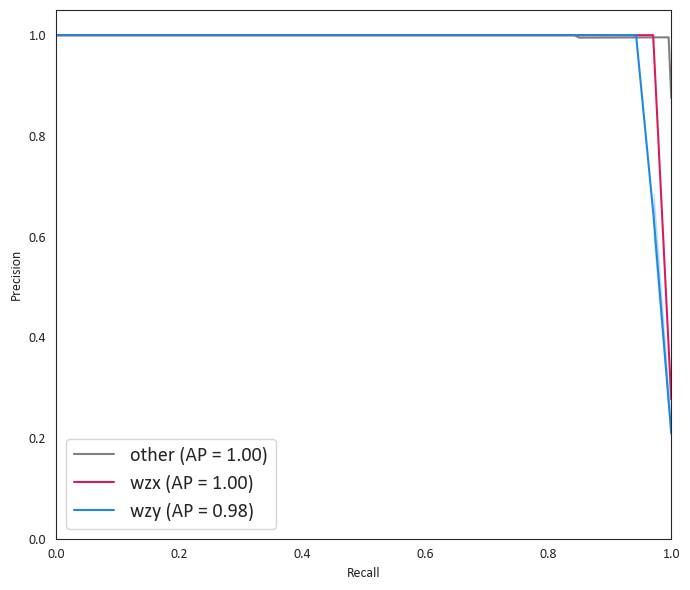

In [59]:
from sklearn.metrics import average_precision_score, precision_recall_curve
from sklearn.preprocessing import label_binarize

y_score = model.predict_proba(X_test)
y_test_bin = label_binarize(y_test, classes=labels)

fig, ax = plt.subplots(figsize=(7, 6))
for i, label in enumerate(labels):
    prec_curve, rec_curve, _ = precision_recall_curve(y_test_bin[:, i], y_score[:, i])
    ap = average_precision_score(y_test_bin[:, i], y_score[:, i])
    sns.lineplot(
        x=rec_curve,
        y=prec_curve,
        color=colors[label],
        label=f"{label} (AP = {ap:.2f})",
        ax=ax,
    )
ax.set(xlabel="Recall", ylabel="Precision")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.legend(fontsize="x-large")
plt.tight_layout()
plt.savefig("pr_curves_wzx_wzy.svg", format="svg")
plt.show()

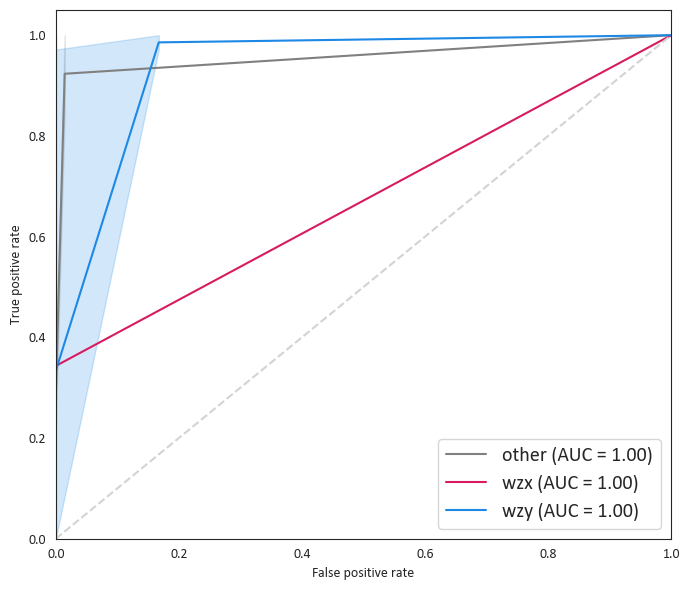

In [60]:
from sklearn.metrics import auc, roc_curve

fig, ax = plt.subplots(figsize=(7, 6))
for i, label in enumerate(labels):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc = auc(fpr, tpr)
    sns.lineplot(
        x=fpr,
        y=tpr,
        color=colors[label],
        label=f"{label} (AUC = {roc_auc:.2f})",
        ax=ax,
    )
ax.plot([0, 1], [0, 1], linestyle="--", color="lightgrey")
ax.set(xlabel="False positive rate", ylabel="True positive rate")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.legend(fontsize="x-large")
plt.tight_layout()
plt.savefig("roc_curves_wzx_wzy.svg", format="svg")
plt.show()

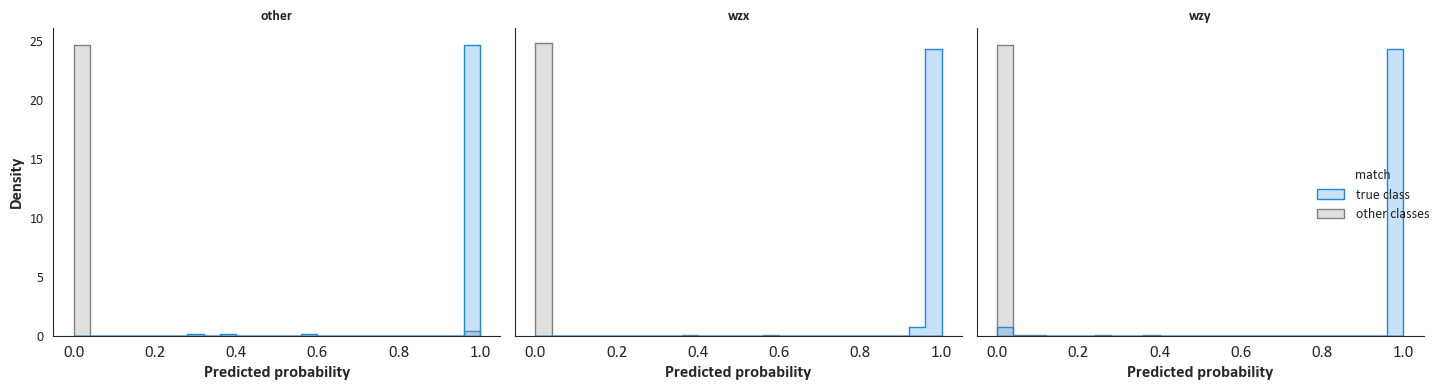

In [61]:
proba_long = pd.DataFrame(y_score, columns=labels).assign(true=y_test).melt(
    id_vars="true", var_name="class", value_name="probability"
)
proba_long["match"] = np.where(
    proba_long["class"] == proba_long["true"], "true class", "other classes"
)

g = sns.displot(
    data=proba_long,
    x="probability",
    hue="match",
    palette={"true class": "#1E88E5", "other classes": "grey"},
    col="class",
    kind="hist",
    bins=25,
    stat="density",
    common_norm=False,
    element="step",
    height=4,
    aspect=1.1,
)
g.set_axis_labels("Predicted probability", "Density", fontsize="large", fontweight="bold")
g.set_titles("{col_name}", fontsize=14, fontweight="bold")
g.tick_params(axis="x", labelsize=12)
g

plt.tight_layout()
plt.savefig("proba_dist_wzx_wzy.svg", format="svg")
plt.show()

In [98]:
import joblib

joblib.dump(model, "wzx_wzy.joblib")

['wzx_wzy.joblib']

Accuracy 0.993421052631579
              precision    recall  f1-score   support

       other       1.00      1.00      1.00       235
         wzx       1.00      0.97      0.99        34
         wzy       0.97      0.97      0.97        35

    accuracy                           0.99       304
   macro avg       0.99      0.98      0.98       304
weighted avg       0.99      0.99      0.99       304

